# MV Oberrhein scalability summary

This notebook reads the merged 5/10/15/20-MG results, displays the summary tables, and plots the mean TR iteration-time breakdown. Plot settings and the plotting function are kept explicit so the figure can be adjusted without changing the experiment code.

In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the repository whether the notebook is started from the project root
# or from a direct child directory.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "stackelberg").is_dir():
    candidate = PROJECT_ROOT.parent
    if (candidate / "stackelberg").is_dir():
        PROJECT_ROOT = candidate
    else:
        raise FileNotFoundError("Run this notebook from the repository root.")

RESULTS_ROOT = PROJECT_ROOT / "results/mv_oberrhein_coptinit_scaling_k10_s1000"
SUMMARY_CSV = RESULTS_ROOT / "scaling_summary.csv"
PLOT_DIR = RESULTS_ROOT / "plots"

# Main plotting interface. Change these values before rerunning the final cell.
PLOT_CONFIG = {
    "style": "seaborn-v0_8-whitegrid",
    "figsize": (8.0, 5.5),
    "bar_width": 3.2,
    "legend_fontsize": 14,
    "legend_location": "upper center",
    "legend_bbox_to_anchor": (0.5, -0.14),
    "legend_ncols": 3,
    "dpi": 180,
    "save": True,  # Set True to export the figure to PLOT_DIR.
    "formats": ("pdf",),
}

if PLOT_CONFIG["style"] in plt.style.available:
    plt.style.use(PLOT_CONFIG["style"])

RESULTS_ROOT

PosixPath('/Users/liqi/Desktop/Codes/Surrogated-assisted Stackelnerg Game/results/mv_oberrhein_coptinit_scaling_k10_s1000')

## Result tables

The first table is the merged scalability summary. The second table reports the NN initial point and final TR result from each per-size history.

In [8]:
REQUIRED_SUMMARY_COLUMNS = {
    "n_microgrids",
    "mean_residual_sampling_seconds",
    "mean_leader_surrogate_solve_seconds",
    "mean_other_iteration_seconds",
    "warm_start_true_objective",
}


def load_scaling_summary(path=SUMMARY_CSV, expected_counts=(5, 10, 15, 20)):
    path = Path(path)
    frame = pd.read_csv(path).sort_values("n_microgrids").reset_index(drop=True)
    missing = REQUIRED_SUMMARY_COLUMNS.difference(frame.columns)
    if missing:
        raise ValueError(f"Missing scaling columns: {sorted(missing)}")
    if frame["n_microgrids"].duplicated().any():
        raise ValueError("scaling_summary.csv contains duplicate microgrid counts.")
    actual = tuple(frame["n_microgrids"].astype(int))
    expected = tuple(int(value) for value in expected_counts)
    if actual != expected:
        raise ValueError(f"Expected microgrid counts {expected}, found {actual}.")
    return frame


def load_objective_summary(summary, results_root=RESULTS_ROOT):
    rows = []
    for item in summary.itertuples(index=False):
        count = int(item.n_microgrids)
        history_path = Path(results_root) / f"mg_{count:02d}" / "timed_history.csv"
        history = pd.read_csv(history_path).sort_values("k").reset_index(drop=True)
        if history.empty:
            raise ValueError(f"Empty history: {history_path}")
        initial = float(item.warm_start_true_objective)
        if not np.isfinite(initial):
            initial = float(history.loc[0, "F_current"])
        final_column = "F_next" if "F_next" in history else "F_current"
        final = float(history.iloc[-1][final_column])
        decision = history.get("decision", pd.Series("", index=history.index)).astype(str)
        rows.append({
            "n_microgrids": count,
            "nn_initial_objective": initial,
            "tr_final_objective": final,
            "objective_improvement": initial - final,
            "accepted_iterations": int(decision.str.startswith("accept").sum()),
            "n_iterations": int(len(history)),
        })
    return pd.DataFrame(rows)


summary = load_scaling_summary()
objective_summary = load_objective_summary(summary)
display(summary)
display(objective_summary)

,n_microgrids,n_bus,n_line,decision_size,n_iterations,stop_reason,tr_elapsed_seconds,seconds_per_iteration,median_seconds_per_iteration,std_seconds_per_iteration,mean_residual_sampling_seconds,mean_leader_surrogate_solve_seconds,mean_other_iteration_seconds,queries_per_iteration,composite_queries,individual_follower_solves,seconds_per_composite_query,equivalent_seconds_per_follower_solve,warm_start_true_objective
0,5,108,107,120,10,max_iterations,7595.912434,759.571893,753.250959,32.393367,54.619324,696.275750,1.379426,61,610,3050,12.452315,2.490463,82.996678
1,10,108,107,240,10,max_iterations,7988.916463,798.873408,802.254707,11.674040,107.174284,682.096489,2.243633,61,610,6100,13.096584,1.309658,-56.957916
2,15,108,107,360,10,max_iterations,8598.627488,859.845935,866.389986,15.346999,161.213496,688.309586,3.134289,61,610,9150,14.096111,0.939741,-196.156157
3,20,108,107,480,10,max_iterations,9278.064895,927.788325,935.507865,23.681140,221.768010,694.731888,4.116296,61,610,12200,15.209942,0.760497,-334.468765


,n_microgrids,nn_initial_objective,tr_final_objective,objective_improvement,accepted_iterations,n_iterations
0,5,82.996678,81.789759,1.206919,5,10
1,10,-56.957916,-59.802547,2.844631,7,10
2,15,-196.156157,-200.492403,4.336247,7,10
3,20,-334.468765,-340.203941,5.735177,9,10


## Mean iteration-time breakdown

`Leader surrogate solve` is drawn first so it occupies the bottom of every stacked bar. Pass an existing Matplotlib axis through `ax=` to place this chart in a different figure layout.

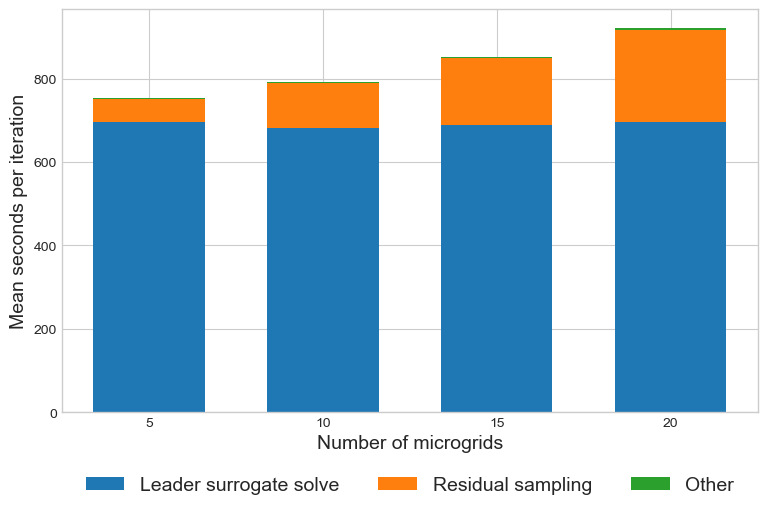

In [9]:
def save_figure(fig, stem, config=PLOT_CONFIG):
    if not config.get("save", False):
        return []
    PLOT_DIR.mkdir(parents=True, exist_ok=True)
    paths = []
    for extension in config.get("formats", ("pdf",)):
        path = PLOT_DIR / f"{stem}.{extension}"
        fig.savefig(path, dpi=config.get("dpi", 180), bbox_inches="tight")
        paths.append(path)
    return paths


def plot_time_breakdown(frame, ax=None, config=PLOT_CONFIG):
    if ax is None:
        fig, ax = plt.subplots(figsize=config["figsize"])
    else:
        fig = ax.figure

    x = frame["n_microgrids"].to_numpy(dtype=int)
    components = {
        # Dictionary order is the vertical stacking order (bottom to top).
        "Leader surrogate solve": frame["mean_leader_surrogate_solve_seconds"].to_numpy(float),
        "Residual sampling": frame["mean_residual_sampling_seconds"].to_numpy(float),
        "Other": frame["mean_other_iteration_seconds"].to_numpy(float),
    }
    bottom = np.zeros(len(frame))
    for label, values in components.items():
        ax.bar(
            x,
            values,
            bottom=bottom,
            width=config.get("bar_width", 3.2),
            label=label,
        )
        bottom += values

    ax.set_xlabel("Number of microgrids", fontsize=14)
    ax.set_ylabel("Mean seconds per iteration", fontsize=14)
    ax.set_xticks(x)
    ax.legend(
        fontsize=config.get("legend_fontsize", 14),
        loc=config.get("legend_location", "upper center"),
        bbox_to_anchor=config.get("legend_bbox_to_anchor", (0.5, -0.14)),
        ncol=config.get("legend_ncols", 3),
        frameon=False,
        borderaxespad=0.0,
    )
    fig.tight_layout()
    fig.subplots_adjust(bottom=0.24)
    save_figure(fig, "scaling_time_breakdown", config)
    return fig, ax


breakdown_fig, breakdown_ax = plot_time_breakdown(summary)